<a href="https://colab.research.google.com/github/ikabrain/UCS772-CV-NLP-Lab/blob/main/NLP_CV_assign7/CV_assign7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 7 - Face Detection
---

In [1]:
!pip uninstall -q -y opencv-python opencv-python-headless opencv-contrib-python
!pip install -q opencv-contrib-python
exit()

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Import the Google Colab specific image display tool
from google.colab.patches import cv2_imshow

## Q1: Detect faces from live images taken from webcam
---

We'll be using the traditional [Haar feature-based cascade classifiers trained with Haar-like features using the Viola-Jones algorithm](https://www.face-rec.org/algorithms/Boosting-Ensemble/16981346.pdf).

Tutorial for same is [here](https://docs.opencv.org/5.0/tutorials_contrib/xobjdetect/cascade_classifier/cascade_classifier.html).

In [2]:
# Install and initialize the Haar Cascade face detection model
!wget -qnc -O haarcascade_frontalface_default.xml https://raw.githubusercontent.com/opencv/opencv/4.x/data/haarcascades/haarcascade_frontalface_default.xml

try:
    face_cascade = cv2.CascadeClassifier('haarcascade_frontalface_default.xml')
    if face_cascade.empty():
        raise FileNotFoundError
except:
    raise FileNotFoundError("Could not load the Haar Cascade face detection model.")

### Capturing webcam image

In [3]:
# @markdown Run this cell to init JS to take photo in Colab using `take_photo` {"vertical-output":true,"form-width":"50%","single-column":true,"display-mode":"form"}
from IPython.display import display, Javascript
from google.colab.output import eval_js
from base64 import b64decode

def take_photo(filename='photo.jpg', quality=0.8):
    js = Javascript('''
        async function takePhoto(quality) {
        const div = document.createElement('div');
        const capture = document.createElement('button');
        capture.textContent = 'Capture';
        div.appendChild(capture);

        const video = document.createElement('video');
        video.style.display = 'block';
        const stream = await navigator.mediaDevices.getUserMedia({video: true});

        document.body.appendChild(div);
        div.appendChild(video);
        video.srcObject = stream;
        await video.play();

        // Resize the output to fit the video element.
        google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);

        // Wait for Capture to be clicked.
        await new Promise((resolve) => capture.onclick = resolve);

        const canvas = document.createElement('canvas');
        canvas.width = video.videoWidth;
        canvas.height = video.videoHeight;
        canvas.getContext('2d').drawImage(video, 0, 0);
        stream.getVideoTracks()[0].stop();
        div.remove();
        return canvas.toDataURL('image/jpeg', quality);
        }
        ''')
    display(js)
    data = eval_js('takePhoto({})'.format(quality))
    binary = b64decode(data.split(',')[1])
    with open(filename, 'wb') as f:
        f.write(binary)
    return filename

<IPython.core.display.Javascript object>

Saved to photo.jpg


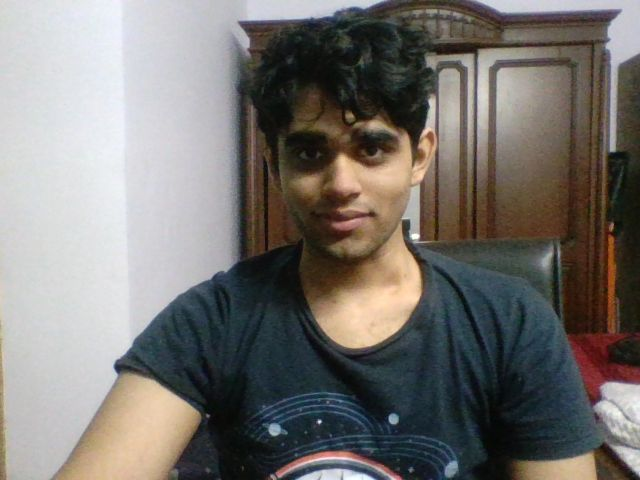

In [4]:
# Capturing photo (saved to `filename`)
from IPython.display import Image

try:
    filename = take_photo("photo.jpg")
    print('Saved to {}'.format(filename))
    display(Image(filename)) # shows the image which was just taken
except Exception as err:
    # Errors will be thrown if the user does not have a webcam or if they do not grant the page permission to access it
    print(str(err))

### Preprocessing the image

In [5]:
# Read and convert the image to grayscale
img = cv2.imread("photo.jpg")
if img is None:
    raise FileNotFoundError("Could not load the target image.")

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

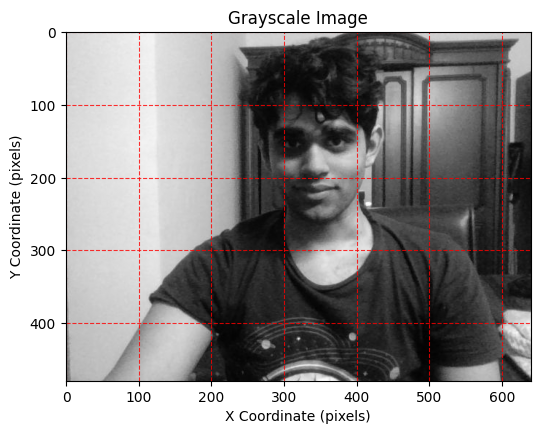

In [6]:
# Plot the image using matplotlib with axes, gridlines, and custom figure size
plt.figure(figsize=(6, 6))
plt.imshow(gray, cmap='gray')
plt.grid(True, color='red', alpha=0.8, linestyle='--')
plt.title("Grayscale Image")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Detecting faces

In [7]:
# 3. Execute Multi-scale Face Detection
# scaleFactor: Dictates image reduction ratio at subsequent pyramid layers (1.1 = 10% reduction)
# minNeighbors: Dictates structural validation density (higher values reduce false positives)
faces = face_cascade.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=10, minSize=(30, 30))

In [8]:
# Enumerate coordinates and generate bound visualization overlays
for (x, y, w, h) in faces:
    cv2.rectangle(img, (x, y), (x + w, y + h), (255, 0, 0), 2)

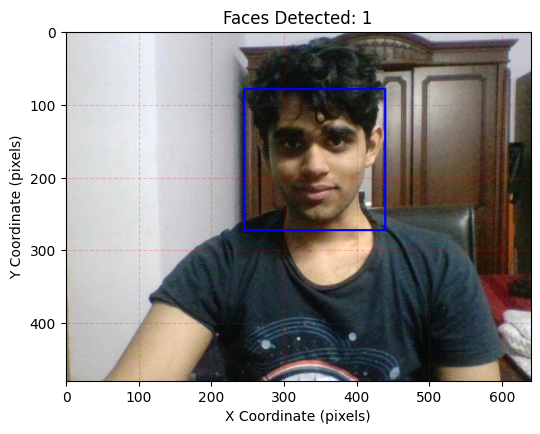

In [9]:
# Display the resulting visualized layer
plt.figure(figsize=(6, 6))
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.grid(True, color='red', alpha=0.2, linestyle='--')
plt.title(f"Faces Detected: {len(faces)}")
plt.xlabel("X Coordinate (pixels)")
plt.ylabel("Y Coordinate (pixels)")
plt.show()

### Q2: Once you're done with images, then take short live video sequence and detect faces
---

## Q3: Detect faces in mask wearing images
---